In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# SHAP Cell 2 — Imports and project path

import os
import numpy as np
import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt

BASE_PATH = "/content/drive/MyDrive/Fraud_Project"

print("SHAP version:", shap.__version__)
print("Project path:", BASE_PATH)
print("Project path exists:", os.path.exists(BASE_PATH))

SHAP version: 0.52.0
Project path: /content/drive/MyDrive/Fraud_Project
Project path exists: True


In [ ]:
# SHAP Cell 3 — Load E3 Hybrid MLP artifacts

e3_mlp = joblib.load(
    os.path.join(BASE_PATH, "E3_Hybrid_MLP_model.pkl")
)

svd = joblib.load(
    os.path.join(BASE_PATH, "E3_Hybrid_MLP_SVD.pkl")
)

e3_mlp_scaler = joblib.load(
    os.path.join(BASE_PATH, "E3_Hybrid_MLP_scaler.pkl")
)

with open(
    os.path.join(BASE_PATH, "E3_Hybrid_MLP_threshold.txt"),
    "r"
) as f:
    E3_MLP_THRESHOLD = float(f.read().strip())

print("E3 Hybrid MLP loaded successfully.")
print("SVD components:", svd.n_components)
print("MLP hidden layers:", e3_mlp.hidden_layer_sizes)
print("MLP iterations:", e3_mlp.n_iter_)
print("Classification threshold:", E3_MLP_THRESHOLD)

E3 Hybrid MLP loaded successfully.
SVD components: 100
MLP hidden layers: (64, 32)
MLP iterations: 35
Classification threshold: 0.01


In [ ]:
# SHAP Cell 4 — Load the fixed E3 test set

test_path = os.path.join(
    BASE_PATH,
    "E1_test.csv"
)

test = pd.read_csv(test_path)

print("Test shape:", test.shape)

print("\nFraud distribution:")
print(test["is_fraud"].value_counts())

print("\nColumns:", len(test.columns))

Test shape: (6185, 23)

Fraud distribution:
is_fraud
0    6121
1      64
Name: count, dtype: int64

Columns: 23


In [ ]:
# SHAP Cell 5 — Recreate E3 financial features

# Load fixed training set
train_path = os.path.join(
    BASE_PATH,
    "E1_train.csv"
)

train = pd.read_csv(train_path)

# Original 12 financial variables
financial_raw_features = [
    "price",
    "Assets",
    "AssetsCurrent",
    "CashAndCashEquivalentsAtCarryingValue",
    "CommonStockSharesIssued",
    "CommonStockValue",
    "IncomeTaxExpenseBenefit",
    "LiabilitiesCurrent",
    "OperatingIncomeLoss",
    "StockholdersEquity",
    "NetIncomeLoss",
    "Liabilities"
]

def create_financial_features(df):
    data = df.copy()

    data["current_ratio"] = (
        data["AssetsCurrent"] /
        data["LiabilitiesCurrent"].replace(0, np.nan)
    )

    data["cash_ratio"] = (
        data["CashAndCashEquivalentsAtCarryingValue"] /
        data["LiabilitiesCurrent"].replace(0, np.nan)
    )

    data["current_assets_ratio"] = (
        data["AssetsCurrent"] /
        data["Assets"].replace(0, np.nan)
    )

    data["liabilities_to_assets"] = (
        data["Liabilities"] /
        data["Assets"].replace(0, np.nan)
    )

    data["debt_to_equity"] = (
        data["Liabilities"] /
        data["StockholdersEquity"].replace(0, np.nan)
    )

    data["roa"] = (
        data["NetIncomeLoss"] /
        data["Assets"].replace(0, np.nan)
    )

    data["roe"] = (
        data["NetIncomeLoss"] /
        data["StockholdersEquity"].replace(0, np.nan)
    )

    data["operating_return_on_assets"] = (
        data["OperatingIncomeLoss"] /
        data["Assets"].replace(0, np.nan)
    )

    data = data.replace([np.inf, -np.inf], np.nan)

    financial_features = financial_raw_features + [
        "current_ratio",
        "cash_ratio",
        "current_assets_ratio",
        "liabilities_to_assets",
        "debt_to_equity",
        "roa",
        "roe",
        "operating_return_on_assets"
    ]

    return data, financial_features


train_fin, financial_features = create_financial_features(train)
test_fin, _ = create_financial_features(test)

print("Number of financial features:", len(financial_features))
print("\nFinancial features:")
print(financial_features)

Number of financial features: 20

Financial features:
['price', 'Assets', 'AssetsCurrent', 'CashAndCashEquivalentsAtCarryingValue', 'CommonStockSharesIssued', 'CommonStockValue', 'IncomeTaxExpenseBenefit', 'LiabilitiesCurrent', 'OperatingIncomeLoss', 'StockholdersEquity', 'NetIncomeLoss', 'Liabilities', 'current_ratio', 'cash_ratio', 'current_assets_ratio', 'liabilities_to_assets', 'debt_to_equity', 'roa', 'roe', 'operating_return_on_assets']


In [ ]:
# SHAP Cell 6 — Impute financial features using training data only

from sklearn.impute import SimpleImputer

X_train_fin = train_fin[financial_features].copy()
X_test_fin = test_fin[financial_features].copy()

financial_imputer = SimpleImputer(strategy="median")

# Fit ONLY on training data
X_train_fin_imp = financial_imputer.fit_transform(X_train_fin)

# Transform test data
X_test_fin_imp = financial_imputer.transform(X_test_fin)

print("Training financial matrix:", X_train_fin_imp.shape)
print("Test financial matrix:", X_test_fin_imp.shape)

print("\nRemaining missing values:")
print("Train:", np.isnan(X_train_fin_imp).sum())
print("Test :", np.isnan(X_test_fin_imp).sum())

Training financial matrix: (18734, 20)
Test financial matrix: (6185, 20)

Remaining missing values:
Train: 0
Test : 0


In [ ]:
# SHAP Cell 7 — Load TF-IDF vectorizer and transform MD&A

tfidf_vectorizer = joblib.load(
    os.path.join(BASE_PATH, "E2_TFIDF_vectorizer.pkl")
)

# Transform MD&A text
X_train_text = tfidf_vectorizer.transform(
    train["mda"]
)

X_test_text = tfidf_vectorizer.transform(
    test["mda"]
)

print("TF-IDF vocabulary size:", len(tfidf_vectorizer.vocabulary_))

print("\nText matrix shapes:")
print("Train:", X_train_text.shape)
print("Test :", X_test_text.shape)

print("\nMatrix type:", type(X_test_text))

TF-IDF vocabulary size: 50000

Text matrix shapes:
Train: (18734, 50000)
Test : (6185, 50000)

Matrix type: <class 'scipy.sparse._csr.csr_matrix'>


In [ ]:
# SHAP Cell 8 — Transform TF-IDF into 100 SVD components

X_train_text_svd = svd.transform(
    X_train_text
)

X_test_text_svd = svd.transform(
    X_test_text
)

print("SVD text shapes:")
print("Train:", X_train_text_svd.shape)
print("Test :", X_test_text_svd.shape)

print("\nExplained variance ratio:",
      svd.explained_variance_ratio_.sum())

print("\nAny NaN:", np.isnan(X_test_text_svd).any())
print("Any Inf:", np.isinf(X_test_text_svd).any())

SVD text shapes:
Train: (18734, 100)
Test : (6185, 100)

Explained variance ratio: 0.19872663153217507

Any NaN: False
Any Inf: False


In [ ]:
# SHAP Cell 9 — Combine financial + SVD text features

X_train_fin_dense = np.asarray(X_train_fin_imp)
X_test_fin_dense = np.asarray(X_test_fin_imp)

# Combine exactly as in E3 MLP
X_train_shap = np.hstack([
    X_train_fin_dense,
    X_train_text_svd
])

X_test_shap = np.hstack([
    X_test_fin_dense,
    X_test_text_svd
])

print("Combined SHAP input shapes:")
print("Train:", X_train_shap.shape)
print("Test :", X_test_shap.shape)

print("\nTotal features:", X_test_shap.shape[1])

print("Any NaN:", np.isnan(X_test_shap).any())
print("Any Inf:", np.isinf(X_test_shap).any())

Combined SHAP input shapes:
Train: (18734, 120)
Test : (6185, 120)

Total features: 120
Any NaN: False
Any Inf: False


In [ ]:
# SHAP Cell 10 — Apply the exact E3 MLP scaler

X_train_shap_scaled = e3_mlp_scaler.transform(
    X_train_shap
)

X_test_shap_scaled = e3_mlp_scaler.transform(
    X_test_shap
)

print("Scaled SHAP input shapes:")
print("Train:", X_train_shap_scaled.shape)
print("Test :", X_test_shap_scaled.shape)

print("\nTraining mean (first 5 features):")
print(X_train_shap_scaled[:, :5].mean(axis=0))

print("\nTraining std (first 5 features):")
print(X_train_shap_scaled[:, :5].std(axis=0))

print("\nAny NaN:", np.isnan(X_test_shap_scaled).any())
print("Any Inf:", np.isinf(X_test_shap_scaled).any())

Scaled SHAP input shapes:
Train: (18734, 120)
Test : (6185, 120)

Training mean (first 5 features):
[ 2.24085271e-17  2.32975567e-17  1.45276007e-16  3.32059445e-16
 -4.25710623e-16]

Training std (first 5 features):
[1. 1. 1. 1. 1.]

Any NaN: False
Any Inf: False


In [ ]:
# SHAP Cell 11 — Verify reconstructed E3 predictions

y_test_shap_prob = e3_mlp.predict_proba(
    X_test_shap_scaled
)[:, 1]

y_test_shap_pred = (
    y_test_shap_prob >= E3_MLP_THRESHOLD
).astype(int)

print("Prediction verification")
print("---------------------------------------")

print("Number of test predictions:", len(y_test_shap_prob))
print("Predicted fraud:", y_test_shap_pred.sum())
print("Actual fraud   :", test["is_fraud"].sum())

print("\nProbability statistics:")
print("Min   :", y_test_shap_prob.min())
print("Max   :", y_test_shap_prob.max())
print("Mean  :", y_test_shap_prob.mean())
print("Median:", np.median(y_test_shap_prob))

print("\nThreshold:", E3_MLP_THRESHOLD)

Prediction verification
---------------------------------------
Number of test predictions: 6185
Predicted fraud: 465
Actual fraud   : 64

Probability statistics:
Min   : 3.3144472081925634e-67
Max   : 0.7372843702947035
Mean  : 0.00477731573384872
Median: 9.855425128793212e-05

Threshold: 0.01


In [ ]:
# SHAP Cell 12 — Select SHAP background and explanation samples

np.random.seed(42)

# Background sample from training data
background_size = 100
background_idx = np.random.choice(
    X_train_shap_scaled.shape[0],
    size=background_size,
    replace=False
)

X_shap_background = X_train_shap_scaled[
    background_idx
]

# Explanation sample from test data
explanation_size = 200
explanation_idx = np.random.choice(
    X_test_shap_scaled.shape[0],
    size=explanation_size,
    replace=False
)

X_shap_explain = X_test_shap_scaled[
    explanation_idx
]

y_shap_explain = test["is_fraud"].values[
    explanation_idx
]

print("SHAP background shape:", X_shap_background.shape)
print("SHAP explanation shape:", X_shap_explain.shape)

print("\nFraud cases in explanation sample:",
      y_shap_explain.sum())

print("Non-fraud cases in explanation sample:",
      (y_shap_explain == 0).sum())

SHAP background shape: (100, 120)
SHAP explanation shape: (200, 120)

Fraud cases in explanation sample: 2
Non-fraud cases in explanation sample: 198


In [ ]:
# SHAP Cell 13 — Create SHAP KernelExplainer

def e3_mlp_probability(X):
    return e3_mlp.predict_proba(X)[:, 1]

explainer = shap.KernelExplainer(
    e3_mlp_probability,
    X_shap_background
)

print("SHAP KernelExplainer created successfully.")
print("Background samples:", X_shap_background.shape[0])
print("Features to explain:", X_shap_background.shape[1])

SHAP KernelExplainer created successfully.
Background samples: 100
Features to explain: 120


In [ ]:
# SHAP Cell 14 — Small SHAP test

X_shap_test = X_shap_explain[:5]

print("Calculating SHAP values for 5 observations...")

shap_test_values = explainer.shap_values(
    X_shap_test,
    nsamples=200
)

print("SHAP calculation completed.")

# Handle SHAP output format
if isinstance(shap_test_values, list):
    shap_test_values = shap_test_values[0]

shap_test_values = np.asarray(shap_test_values)

print("SHAP values shape:", shap_test_values.shape)
print("Expected shape:", X_shap_test.shape)

Calculating SHAP values for 5 observations...


  0%|          | 0/5 [00:00<?, ?it/s]

SHAP calculation completed.
SHAP values shape: (5, 120)
Expected shape: (5, 120)


In [ ]:
# SHAP Cell 15 — Calculate SHAP values for the explanation sample

print("Calculating SHAP values for 200 test observations...")

shap_values = explainer.shap_values(
    X_shap_explain,
    nsamples=200
)

# Handle SHAP output format
if isinstance(shap_values, list):
    shap_values = shap_values[0]

shap_values = np.asarray(shap_values)

print("\nSHAP calculation completed.")
print("SHAP values shape:", shap_values.shape)
print("Input shape      :", X_shap_explain.shape)

Calculating SHAP values for 200 test observations...


  0%|          | 0/200 [00:00<?, ?it/s]


SHAP calculation completed.
SHAP values shape: (200, 120)
Input shape      : (200, 120)


In [ ]:
# SHAP Cell 16 — Create feature names

financial_feature_names = financial_features.copy()

text_feature_names = [
    f"SVD_Text_{i+1}"
    for i in range(svd.n_components)
]

shap_feature_names = (
    financial_feature_names +
    text_feature_names
)

print("Total feature names:", len(shap_feature_names))

print("\nFirst 20 features:")
print(shap_feature_names[:20])

print("\nLast 5 features:")
print(shap_feature_names[-5:])

Total feature names: 120

First 20 features:
['price', 'Assets', 'AssetsCurrent', 'CashAndCashEquivalentsAtCarryingValue', 'CommonStockSharesIssued', 'CommonStockValue', 'IncomeTaxExpenseBenefit', 'LiabilitiesCurrent', 'OperatingIncomeLoss', 'StockholdersEquity', 'NetIncomeLoss', 'Liabilities', 'current_ratio', 'cash_ratio', 'current_assets_ratio', 'liabilities_to_assets', 'debt_to_equity', 'roa', 'roe', 'operating_return_on_assets']

Last 5 features:
['SVD_Text_96', 'SVD_Text_97', 'SVD_Text_98', 'SVD_Text_99', 'SVD_Text_100']


In [ ]:
# SHAP Cell 17 — Global SHAP feature importance

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "feature": shap_feature_names,
    "mean_abs_shap": mean_abs_shap
})

# Sort from most important to least important
shap_importance_df = (
    shap_importance_df
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

print("Top 20 SHAP features:")
display(shap_importance_df.head(20))

Top 20 SHAP features:


,feature,mean_abs_shap
0,SVD_Text_4,0.001573
1,SVD_Text_23,0.000919
2,SVD_Text_14,0.000710
3,SVD_Text_50,0.000643
4,SVD_Text_7,0.000576
5,SVD_Text_21,0.000574
6,StockholdersEquity,0.000404
7,SVD_Text_41,0.000400
8,CommonStockValue,0.000382
9,SVD_Text_56,0.000349


In [ ]:
# SHAP Cell 18 — Compare financial vs. text contribution

financial_shap_importance = (
    shap_importance_df[
        shap_importance_df["feature"].isin(financial_feature_names)
    ]["mean_abs_shap"].sum()
)

text_shap_importance = (
    shap_importance_df[
        shap_importance_df["feature"].isin(text_feature_names)
    ]["mean_abs_shap"].sum()
)

total_shap_importance = (
    financial_shap_importance + text_shap_importance
)

financial_percentage = (
    financial_shap_importance /
    total_shap_importance * 100
)

text_percentage = (
    text_shap_importance /
    total_shap_importance * 100
)

print("Global SHAP contribution by feature group")
print("--------------------------------------------")

print("Financial features:")
print("Total mean |SHAP|:", financial_shap_importance)
print("Percentage      :", financial_percentage, "%")

print("\nText/SVD features:")
print("Total mean |SHAP|:", text_shap_importance)
print("Percentage      :", text_percentage, "%")

print("\nTotal:")
print(total_shap_importance)

Global SHAP contribution by feature group
--------------------------------------------
Financial features:
Total mean |SHAP|: 0.0023074536830375793
Percentage      : 11.908016187634992 %

Text/SVD features:
Total mean |SHAP|: 0.017069860276558695
Percentage      : 88.09198381236502 %

Total:
0.019377313959596274


In [ ]:
# SHAP Cell 19 — Financial feature importance

financial_shap_df = (
    shap_importance_df[
        shap_importance_df["feature"].isin(financial_feature_names)
    ]
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

print("Financial Features — SHAP Importance")
print("--------------------------------------")

display(financial_shap_df)

Financial Features — SHAP Importance
--------------------------------------


,feature,mean_abs_shap
0,StockholdersEquity,0.000404
1,CommonStockValue,0.000382
2,current_assets_ratio,0.000237
3,Assets,0.000129
4,OperatingIncomeLoss,0.000119
5,operating_return_on_assets,0.000108
6,CashAndCashEquivalentsAtCarryingValue,0.000095
7,price,0.000094
8,IncomeTaxExpenseBenefit,0.000090
9,Liabilities,0.000088


In [ ]:
# SHAP Cell 20 — Direction of financial feature contributions

financial_indices = [
    shap_feature_names.index(feature)
    for feature in financial_feature_names
]

financial_signed_shap = shap_values[
    :, financial_indices
].mean(axis=0)

financial_direction_df = pd.DataFrame({
    "feature": financial_feature_names,
    "mean_abs_shap": np.abs(
        shap_values[:, financial_indices]
    ).mean(axis=0),
    "mean_signed_shap": financial_signed_shap
})

financial_direction_df = (
    financial_direction_df
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

print("Financial SHAP importance and direction")
print("----------------------------------------")

display(financial_direction_df)

Financial SHAP importance and direction
----------------------------------------


,feature,mean_abs_shap,mean_signed_shap
0,StockholdersEquity,0.000404,-0.000073
1,CommonStockValue,0.000382,-0.000247
2,current_assets_ratio,0.000237,-0.000151
3,Assets,0.000129,0.000012
4,OperatingIncomeLoss,0.000119,0.000012
5,operating_return_on_assets,0.000108,-0.000017
6,CashAndCashEquivalentsAtCarryingValue,0.000095,-0.000058
7,price,0.000094,0.000003
8,IncomeTaxExpenseBenefit,0.000090,-0.000090
9,Liabilities,0.000088,0.000020


In [ ]:
# SHAP Cell 21 — SVD/text feature importance

text_shap_df = (
    shap_importance_df[
        shap_importance_df["feature"].isin(text_feature_names)
    ]
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

print("Top 20 SVD/Text Features — SHAP Importance")
print("--------------------------------------------")

display(text_shap_df.head(20))

Top 20 SVD/Text Features — SHAP Importance
--------------------------------------------


,feature,mean_abs_shap
0,SVD_Text_4,0.001573
1,SVD_Text_23,0.000919
2,SVD_Text_14,0.000710
3,SVD_Text_50,0.000643
4,SVD_Text_7,0.000576
5,SVD_Text_21,0.000574
6,SVD_Text_41,0.000400
7,SVD_Text_56,0.000349
8,SVD_Text_24,0.000314
9,SVD_Text_57,0.000313


/tmp/ipykernel_4849/231470174.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


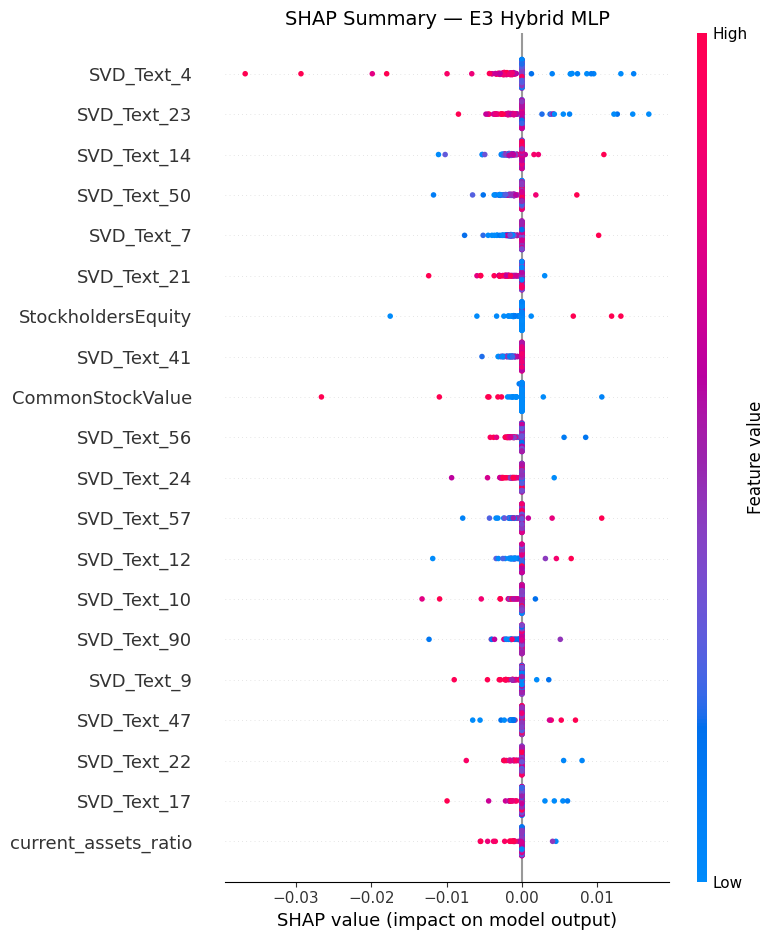

Figure saved to:
/content/drive/MyDrive/Fraud_Project/E3_Hybrid_MLP_SHAP_Summary.png


In [ ]:
# SHAP Cell 22 — SHAP summary plot

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values,
    X_shap_explain,
    feature_names=shap_feature_names,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary — E3 Hybrid MLP",
    fontsize=14
)

plt.tight_layout()

# Save figure
shap_summary_path = os.path.join(
    BASE_PATH,
    "E3_Hybrid_MLP_SHAP_Summary.png"
)

plt.savefig(
    shap_summary_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(shap_summary_path)

In [ ]:
# SHAP Cell 23 — Save SHAP importance results

shap_importance_path = os.path.join(
    BASE_PATH,
    "E3_Hybrid_MLP_SHAP_feature_importance.csv"
)

shap_importance_df.to_csv(
    shap_importance_path,
    index=False
)

financial_shap_path = os.path.join(
    BASE_PATH,
    "E3_Hybrid_MLP_SHAP_financial_features.csv"
)

financial_direction_df.to_csv(
    financial_shap_path,
    index=False
)

text_shap_path = os.path.join(
    BASE_PATH,
    "E3_Hybrid_MLP_SHAP_text_features.csv"
)

text_shap_df.to_csv(
    text_shap_path,
    index=False
)

print("SHAP result files saved successfully.")

print("\n1.", shap_importance_path)
print("2.", financial_shap_path)
print("3.", text_shap_path)

SHAP result files saved successfully.

1. /content/drive/MyDrive/Fraud_Project/E3_Hybrid_MLP_SHAP_feature_importance.csv
2. /content/drive/MyDrive/Fraud_Project/E3_Hybrid_MLP_SHAP_financial_features.csv
3. /content/drive/MyDrive/Fraud_Project/E3_Hybrid_MLP_SHAP_text_features.csv


In [ ]:
# SHAP Cell 24 — Identify fraud cases for individual explanations

# Test probabilities from the verified E3 MLP
test_probabilities = y_test_shap_prob

# Create a compact test-result table
test_explanation_df = test[
    ["cik", "fiscal_year", "is_fraud"]
].copy()

test_explanation_df["fraud_probability"] = test_probabilities

test_explanation_df["predicted_fraud"] = (
    test_probabilities >= E3_MLP_THRESHOLD
).astype(int)

# Keep actual fraud cases only
fraud_cases = (
    test_explanation_df[
        test_explanation_df["is_fraud"] == 1
    ]
    .sort_values("fraud_probability", ascending=False)
    .reset_index()
)

print("Actual fraud cases in test set:", len(fraud_cases))

print("\nTop 10 actual fraud cases by predicted probability:")
display(
    fraud_cases[
        [
            "index",
            "cik",
            "fiscal_year",
            "fraud_probability",
            "predicted_fraud"
        ]
    ].head(10)
)

Actual fraud cases in test set: 64

Top 10 actual fraud cases by predicted probability:


,index,cik,fiscal_year,fraud_probability,predicted_fraud
0,3194,1637459,2017,0.308995,1
1,3195,1637459,2018,0.103885,1
2,2695,773840,2011,0.095194,1
3,3193,1637459,2016,0.095038,1
4,2696,773840,2012,0.058906,1
5,396,317788,2017,0.056760,1
6,397,317788,2018,0.039508,1
7,4440,79879,2018,0.029441,1
8,2697,773840,2013,0.012968,1
9,2694,773840,2010,0.012880,1


In [ ]:
# SHAP Cell 25 — Local explanation for a representative fraud case

# Select the highest-probability actual fraud case
representative_index = fraud_cases.iloc[0]["index"]

# Locate its position in the original test matrix
test_position = test.index.get_loc(representative_index)

# Extract the corresponding scaled feature vector
X_representative = X_test_shap_scaled[
    test_position:test_position + 1
]

# Calculate SHAP values
print("Calculating local SHAP explanation...")

representative_shap_values = explainer.shap_values(
    X_representative,
    nsamples=200
)

if isinstance(representative_shap_values, list):
    representative_shap_values = representative_shap_values[0]

representative_shap_values = np.asarray(
    representative_shap_values
).reshape(-1)

print("\nLocal SHAP calculation completed.")
print("Number of SHAP values:", len(representative_shap_values))

print("\nRepresentative case:")
print("CIK:", test.loc[representative_index, "cik"])
print("Fiscal year:", test.loc[representative_index, "fiscal_year"])
print("Actual label:", test.loc[representative_index, "is_fraud"])
print("Fraud probability:", test_probabilities[test_position])

Calculating local SHAP explanation...


  0%|          | 0/1 [00:00<?, ?it/s]


Local SHAP calculation completed.
Number of SHAP values: 120

Representative case:
CIK: 1637459
Fiscal year: 2017
Actual label: 1
Fraud probability: 0.30899537546627204


In [ ]:
# SHAP Cell 26 — Rank local SHAP contributions

local_shap_df = pd.DataFrame({
    "feature": shap_feature_names,
    "shap_value": representative_shap_values,
    "abs_shap_value": np.abs(representative_shap_values)
})

# Sort by absolute contribution
local_shap_df = (
    local_shap_df
    .sort_values("abs_shap_value", ascending=False)
    .reset_index(drop=True)
)

print("Top 20 features influencing the representative fraud case")
print("------------------------------------------------------------")

display(
    local_shap_df.head(20)
)

Top 20 features influencing the representative fraud case
------------------------------------------------------------


,feature,shap_value,abs_shap_value
0,StockholdersEquity,0.053873,0.053873
1,SVD_Text_34,0.036942,0.036942
2,SVD_Text_92,0.031964,0.031964
3,SVD_Text_14,0.030804,0.030804
4,SVD_Text_94,0.029341,0.029341
5,SVD_Text_68,0.028067,0.028067
6,LiabilitiesCurrent,0.027247,0.027247
7,SVD_Text_100,0.024264,0.024264
8,SVD_Text_95,0.019248,0.019248
9,SVD_Text_87,0.013496,0.013496


In [ ]:
# SHAP Cell 27 — Positive and negative local contributions

positive_local = (
    local_shap_df[
        local_shap_df["shap_value"] > 0
    ]
    .sort_values("shap_value", ascending=False)
    .reset_index(drop=True)
)

negative_local = (
    local_shap_df[
        local_shap_df["shap_value"] < 0
    ]
    .sort_values("shap_value")
    .reset_index(drop=True)
)

print("Features pushing toward higher fraud probability:")
print("------------------------------------------------")
display(positive_local.head(15))

print("\nFeatures pushing toward lower fraud probability:")
print("------------------------------------------------")
display(negative_local.head(15))

# Save local explanation
local_shap_path = os.path.join(
    BASE_PATH,
    "E3_Hybrid_MLP_SHAP_representative_fraud_case.csv"
)

local_shap_df.to_csv(
    local_shap_path,
    index=False
)

print("\nLocal SHAP explanation saved to:")
print(local_shap_path)

Features pushing toward higher fraud probability:
------------------------------------------------


,feature,shap_value,abs_shap_value
0,StockholdersEquity,0.053873,0.053873
1,SVD_Text_34,0.036942,0.036942
2,SVD_Text_92,0.031964,0.031964
3,SVD_Text_14,0.030804,0.030804
4,SVD_Text_94,0.029341,0.029341
5,SVD_Text_68,0.028067,0.028067
6,LiabilitiesCurrent,0.027247,0.027247
7,SVD_Text_100,0.024264,0.024264
8,SVD_Text_95,0.019248,0.019248
9,SVD_Text_87,0.013496,0.013496



Features pushing toward lower fraud probability:
------------------------------------------------


,feature,shap_value,abs_shap_value



Local SHAP explanation saved to:
/content/drive/MyDrive/Fraud_Project/E3_Hybrid_MLP_SHAP_representative_fraud_case.csv


In [ ]:
# SHAP Cell 28 — Clean local explanation table

local_explanation = (
    local_shap_df[
        local_shap_df["abs_shap_value"] > 1e-6
    ]
    .copy()
)

local_explanation["direction"] = np.where(
    local_explanation["shap_value"] > 0,
    "Toward higher fraud probability",
    "Toward lower fraud probability"
)

local_explanation = local_explanation[
    [
        "feature",
        "shap_value",
        "direction"
    ]
]

print("Representative Fraud Case — Local SHAP Explanation")
print("---------------------------------------------------")

display(local_explanation)

# Save clean version
clean_local_path = os.path.join(
    BASE_PATH,
    "E3_Hybrid_MLP_SHAP_representative_clean.csv"
)

local_explanation.to_csv(
    clean_local_path,
    index=False
)

print("\nClean local explanation saved to:")
print(clean_local_path)

Representative Fraud Case — Local SHAP Explanation
---------------------------------------------------


,feature,shap_value,direction
0,StockholdersEquity,0.053873,Toward higher fraud probability
1,SVD_Text_34,0.036942,Toward higher fraud probability
2,SVD_Text_92,0.031964,Toward higher fraud probability
3,SVD_Text_14,0.030804,Toward higher fraud probability
4,SVD_Text_94,0.029341,Toward higher fraud probability
5,SVD_Text_68,0.028067,Toward higher fraud probability
6,LiabilitiesCurrent,0.027247,Toward higher fraud probability
7,SVD_Text_100,0.024264,Toward higher fraud probability
8,SVD_Text_95,0.019248,Toward higher fraud probability
9,SVD_Text_87,0.013496,Toward higher fraud probability



Clean local explanation saved to:
/content/drive/MyDrive/Fraud_Project/E3_Hybrid_MLP_SHAP_representative_clean.csv
